<a href="https://colab.research.google.com/github/ZackyRioOrlando/Praktikum-Pembelajaran-Mesin-/blob/main/JS07/JS07-TugasLab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


1. Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_credit_card. Apakah sebaran data dapat dikatakan linier?

2. Buatlah model klasterisasi dengan menggunakan model K-Means. Tentukan jumlah
k
k yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

3. Gambarkan hasil klasterisasi dengan model K-Means dengan menggunakan scatterplot.

4. Buatlah model klasterisasi dengan menggunakan DBSCAN dengan seluruh variabel yang dapat digunakan.

5. Tentukan jumlah
k
k yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

6. Tentukan nilai silhouette score dan DBI dari model DBSCAN.

Langkah 1 - Import Library dan Baca Dataset

In [1]:
from google.colab import files

uploaded = files.upload()

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Membaca dataset
df = pd.read_csv('/content/CC_Customer_Dataset.csv')

# Melihat lima data pertama
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


Langkah 2 - Periksa informasi dataset dan pastikan nama kolom sesuai.

In [3]:
print(df.shape)
print(df.columns.tolist())
print(df.info())
print(df.isnull().sum())

(660, 7)
['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB
None
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64


Langkah 3 - Tentukan variabel yang akan digunakan untuk klasterisasi.

In [4]:
fitur = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]

X = df[fitur]

# Standardisasi seluruh variabel numerik
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Jumlah data:', X.shape[0])
print('Jumlah variabel:', X.shape[1])

Jumlah data: 660
Jumlah variabel: 5


Soal 1. Membuat scatterplot dan menentukan hubungan linier

Langkah 1 - Buat scatterplot menggunakan variabel Avg_Credit_Limit dan Total_Credit_Cards.

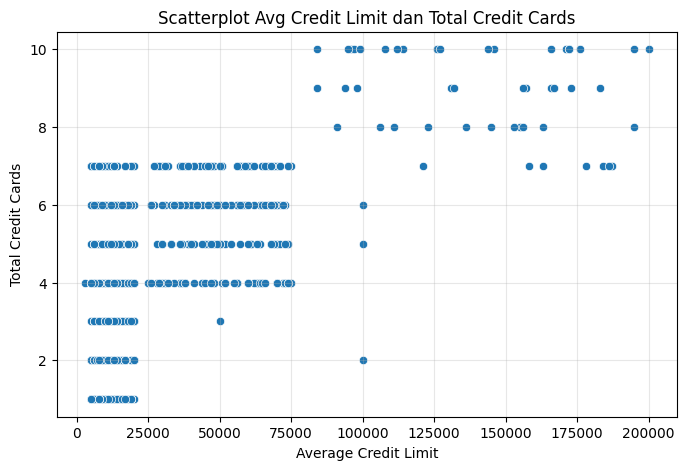

In [6]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards'
)

plt.title('Scatterplot Avg Credit Limit dan Total Credit Cards')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.grid(alpha=0.3)
plt.show()

Langkah 2 - Hitung koefisien korelasi untuk membantu menganalisis hubungan kedua variabel.

In [7]:
korelasi = df['Avg_Credit_Limit'].corr(
    df['Total_Credit_Cards']
)

print('Koefisien korelasi:', round(korelasi, 3))

Koefisien korelasi: 0.609


Berdasarkan scatterplot antara variabel Avg_Credit_Limit dan Total_Credit_Cards, terlihat bahwa sebaran data cenderung menunjukkan hubungan positif, yaitu pelanggan dengan rata-rata batas kredit yang lebih tinggi cenderung memiliki jumlah kartu kredit yang lebih banyak. Hasil perhitungan koefisien korelasi sebesar 0,609 menunjukkan adanya hubungan positif dengan kekuatan sedang antara kedua variabel. Namun, titik-titik data tidak membentuk garis lurus secara konsisten, sehingga hubungan kedua variabel dapat dikatakan memiliki kecenderungan positif, tetapi tidak sepenuhnya linier


2. Buatlah model klasterisasi dengan menggunakan model K-Means. Tentukan jumlah
k
k yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

Langkah 1 - Gunakan data yang telah distandardisasi pada bagian persiapan, yaitu X_scaled.

Langkah 2 - Hitung nilai WCSS untuk \(k=1\) sampai \(k=10\).

In [8]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

print('Nilai WCSS:')
for k, nilai in enumerate(wcss, start=1):
    print(f'k = {k}: {nilai:.2f}')

Nilai WCSS:
k = 1: 3300.00
k = 2: 2040.99
k = 3: 933.04
k = 4: 780.77
k = 5: 704.48
k = 6: 642.27
k = 7: 599.93
k = 8: 567.33
k = 9: 542.25
k = 10: 516.24


Langkah 3 - Buat linechart elbow method.

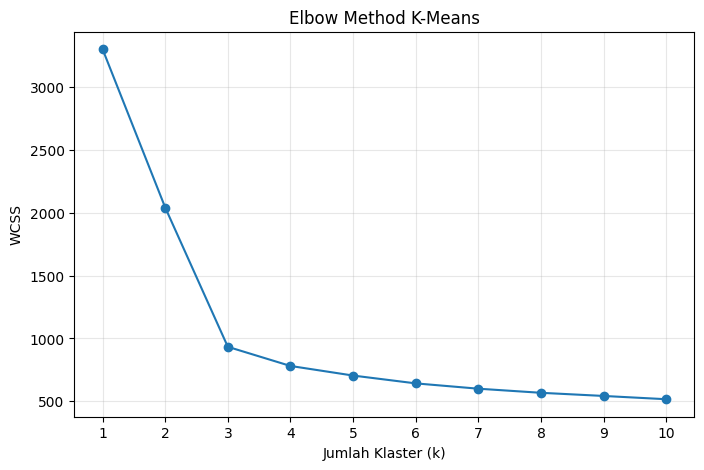

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.title('Elbow Method K-Means')
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.show()

Berdasarkan hasil klasterisasi menggunakan algoritma K-Means dan grafik elbow method, nilai WCSS mengalami penurunan yang cukup tajam dari \(k=1\) sebesar 3300,00 hingga \(k=3\) sebesar 933,04. Setelah \(k=3\), penurunan nilai WCSS mulai melambat, sehingga grafik membentuk titik siku pada \(k=3\). Oleh karena itu, jumlah klaster terbaik yang dipilih adalah 3 klaster, karena dapat memberikan keseimbangan antara kekompakan data dalam klaster dan jumlah klaster yang digunakan.

3. Gambarkan hasil klasterisasi dengan model K-Means dengan menggunakan scatterplot.

Langkah 1 - Gunakan nilai \(k\) terbaik yang diperoleh dari soal nomor 2.

Langkah 2 - Buat dan jalankan model K-Means.

In [10]:
k_terbaik = 3

model_kmeans = KMeans(
    n_clusters=k_terbaik,
    random_state=42,
    n_init=10
)

df['Cluster_KMeans'] = model_kmeans.fit_predict(X_scaled)

print(df['Cluster_KMeans'].value_counts().sort_index())

Cluster_KMeans
0    386
1     50
2    224
Name: count, dtype: int64


Langkah 3 - Visualisasikan hasil klaster menggunakan dua variabel yang diminta pada soal nomor 1.

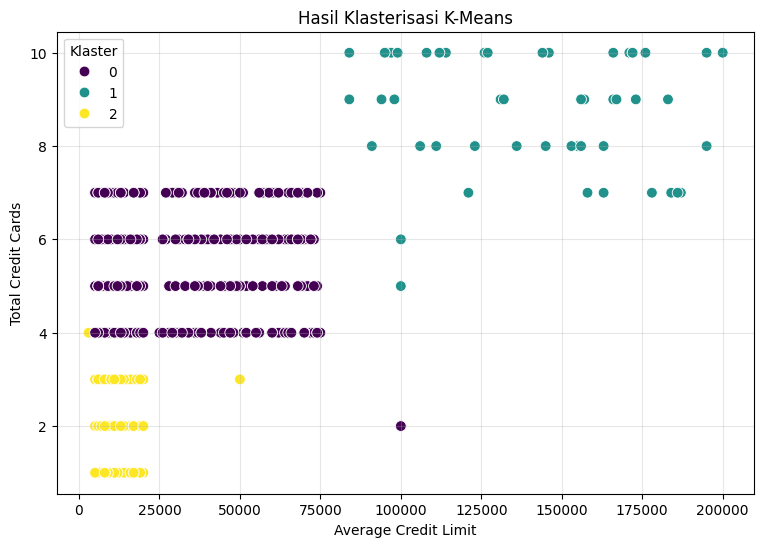

In [11]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='Cluster_KMeans',
    palette='viridis',
    s=60
)

plt.title('Hasil Klasterisasi K-Means')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.legend(title='Klaster')
plt.grid(alpha=0.3)
plt.show()


4. Buatlah model klasterisasi dengan menggunakan DBSCAN dengan seluruh variabel yang dapat digunakan.

Langkah 1 - Pastikan lima variabel numerik sudah disiapkan dan distandardisasi pada bagian persiapan.

Variabel tersebut adalah Avg_Credit_Limit, Total_Credit_Cards, Total_visits_bank, Total_visits_online, dan Total_calls_made.

Langkah 2 - Buat model DBSCAN.

In [12]:
model_dbscan = DBSCAN(
    eps=1.0,
    min_samples=8
)

df['Cluster_DBSCAN'] = model_dbscan.fit_predict(X_scaled)

Langkah 3 - Tampilkan jumlah anggota masing-masing klaster

In [13]:
print('Jumlah anggota setiap klaster DBSCAN:')

print(
    df['Cluster_DBSCAN']
    .value_counts()
    .sort_index()
)

Jumlah anggota setiap klaster DBSCAN:
Cluster_DBSCAN
-1     40
 0    608
 1     12
Name: count, dtype: int64


Langkah 4 - Hitung jumlah klaster dan data noise.

In [14]:
label_dbscan = df['Cluster_DBSCAN']

jumlah_klaster = len(set(label_dbscan)) - (
    1 if -1 in label_dbscan.values else 0
)

jumlah_noise = (label_dbscan == -1).sum()

print('Jumlah klaster:', jumlah_klaster)
print('Jumlah data noise:', jumlah_noise)

Jumlah klaster: 2
Jumlah data noise: 40



5. Tentukan jumlah
k
k yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

Berdasarkan linechart elbow method, nilai WCSS mengalami penurunan yang cukup tajam dari 3300,00 pada \(k=1\) menjadi 933,04 pada \(k=3\). Setelah \(k=3\), penurunan WCSS mulai melambat, yang ditunjukkan oleh garis grafik yang semakin landai. Oleh karena itu, jumlah klaster terbaik adalah \(k=3\) karena titik tersebut merupakan titik siku pada grafik dan memberikan keseimbangan antara kekompakan klaster dan jumlah klaster yang digunakan.


6. Tentukan nilai silhouette score dan DBI dari model DBSCAN.

Langkah 1 - Ambil label klaster yang dihasilkan model DBSCAN.

Langkah 2 - Periksa jumlah klaster selain noise.

In [15]:
label_dbscan = df['Cluster_DBSCAN'].values

mask = label_dbscan != -1

X_valid = X_scaled[mask]
label_valid = label_dbscan[mask]

jumlah_klaster_valid = len(set(label_valid))

print('Jumlah klaster tanpa noise:', jumlah_klaster_valid)
print('Jumlah data tanpa noise:', mask.sum())

Jumlah klaster tanpa noise: 2
Jumlah data tanpa noise: 620


Langkah 3 - Hitung Silhouette Score dan DBI pada data non-noise jika terdapat setidaknya dua klaster.

In [16]:
if jumlah_klaster_valid >= 2:
    silhouette = silhouette_score(
        X_valid,
        label_valid
    )

    dbi = davies_bouldin_score(
        X_valid,
        label_valid
    )

    print('Silhouette Score:', round(silhouette, 4))
    print('Davies-Bouldin Index:', round(dbi, 4))
else:
    print(
        'Metrik tidak dapat dihitung karena '
        'jumlah klaster non-noise kurang dari dua.'
    )

Silhouette Score: 0.5899
Davies-Bouldin Index: 0.4694
